# ME5411 Robot Vision and AI Project
> Group 33  

## Import libraries

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from preprocessing import *
from utils import *

## Task 1: Display Image
Display the original image on screen. Experiment with contrast enhancement of the image. Comment on the results.

a. Display Original Image

In [2]:
CODE_DIR = Path.cwd()
test_img_path = CODE_DIR / "Test_Image_2026.bmp" 
test_img = cv2.imread(str(test_img_path))
test_img.shape

(367, 990, 3)

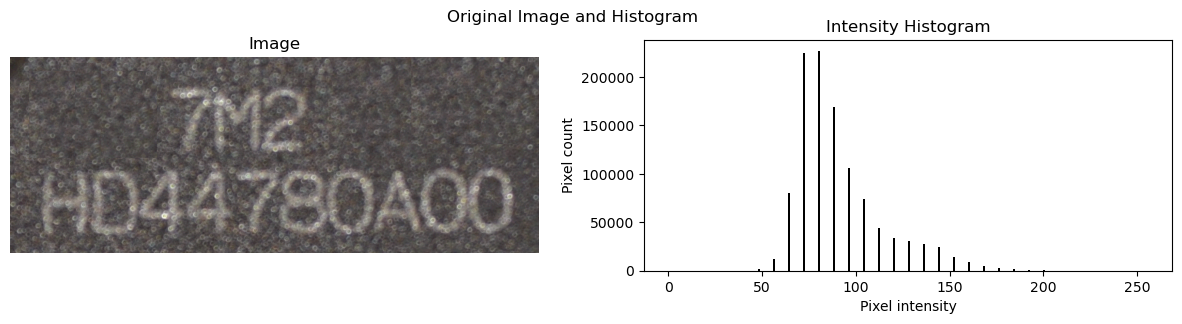

In [3]:
plot_img_hist([test_img], title="Original Image and Histogram")

b. Original Image in Grayscale

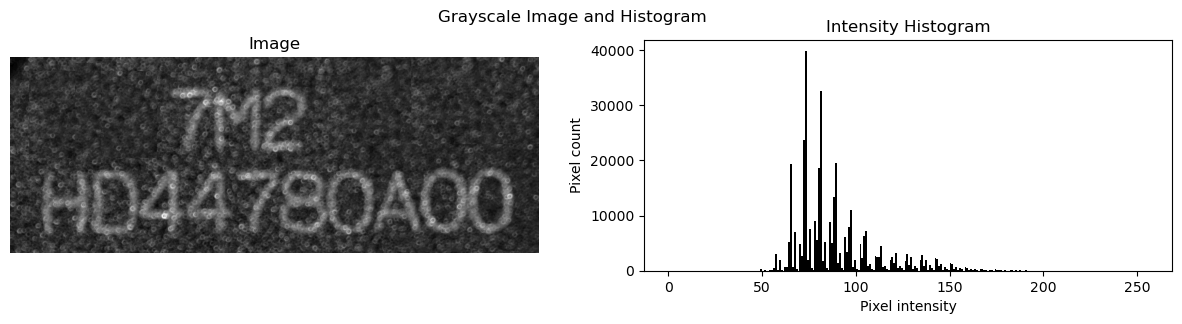

In [4]:
test_img_gray = cv2.cvtColor(test_img, cv2.COLOR_BGR2GRAY)
plot_img_hist([test_img_gray], title="Grayscale Image and Histogram")

c. Contrast Control

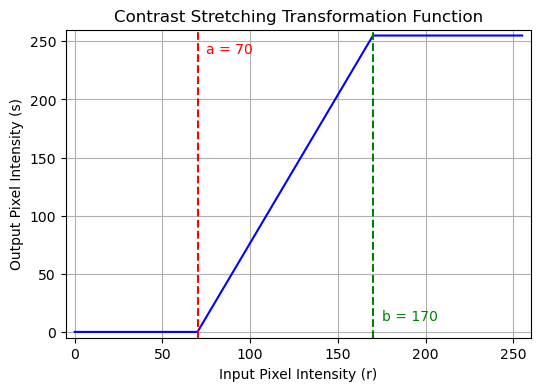

In [5]:
# Constrast Stretching
test_img_stretched = contrast_stretching(test_img_gray, a=70, b=170, show_transform=True)
# plot_img_hist(test_img_stretched, title="Contrast Stretched Image and Histogram")

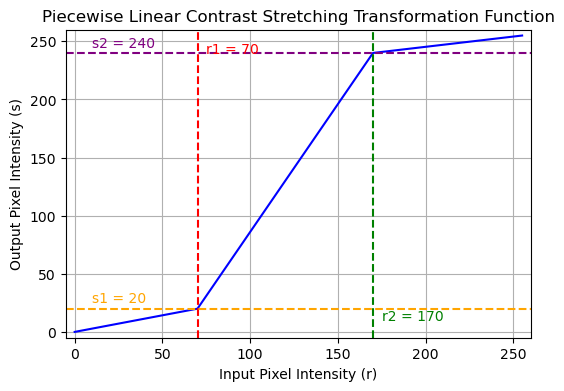

In [6]:
# Constrast Stretching Piecewise
test_img_stretched_piecewise = contrast_stretching_piecewise(test_img_gray, r1=70, r2=170, s1=20, s2=240, show_transform=True)
# plot_img_hist(test_img_stretched_piecewise, title="Contrast Stretched Piecewise Image and Histogram")

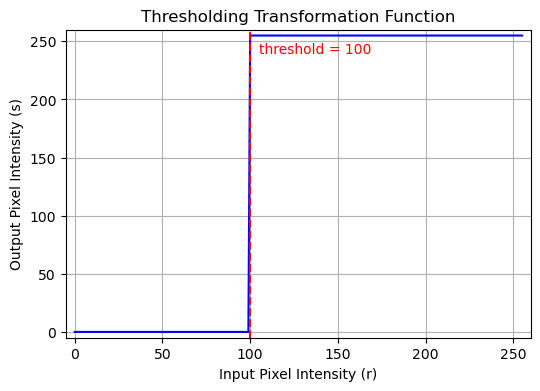

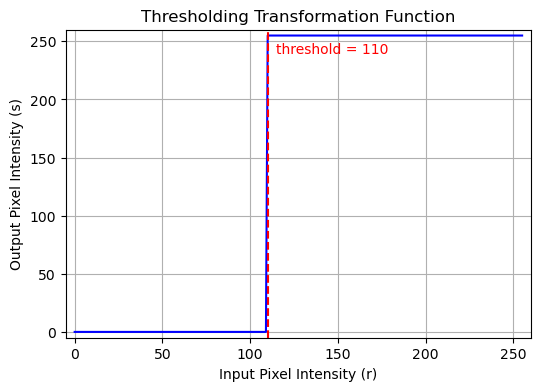

In [7]:
# Thresholding
test_img_thresholded_1 = thresholding(test_img_gray, threshold=100, show_transform=True)
# plot_img_hist(test_img_thresholded_1, title="Thresholded Image and Histogram")
test_img_thresholded_2 = thresholding(test_img_gray, threshold=110, show_transform=True)
# plot_img_hist(test_img_thresholded_2, title="Thresholded Image and Histogram")

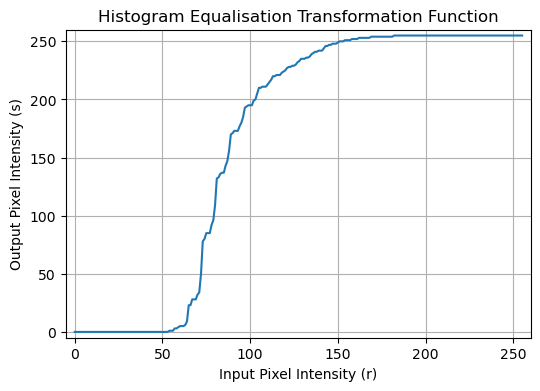

In [8]:
# Histogram equalization
test_img_eq = histogram_equalization(test_img_gray, show_transform=True)
# plot_img_hist(test_img_eq, title="Histogram Equalized Image and Histogram")

In [9]:
# CLAHE
test_img_clahe = clahe_equalization(test_img_gray, clip_limit=1.2, tile_grid_size=(4, 4))

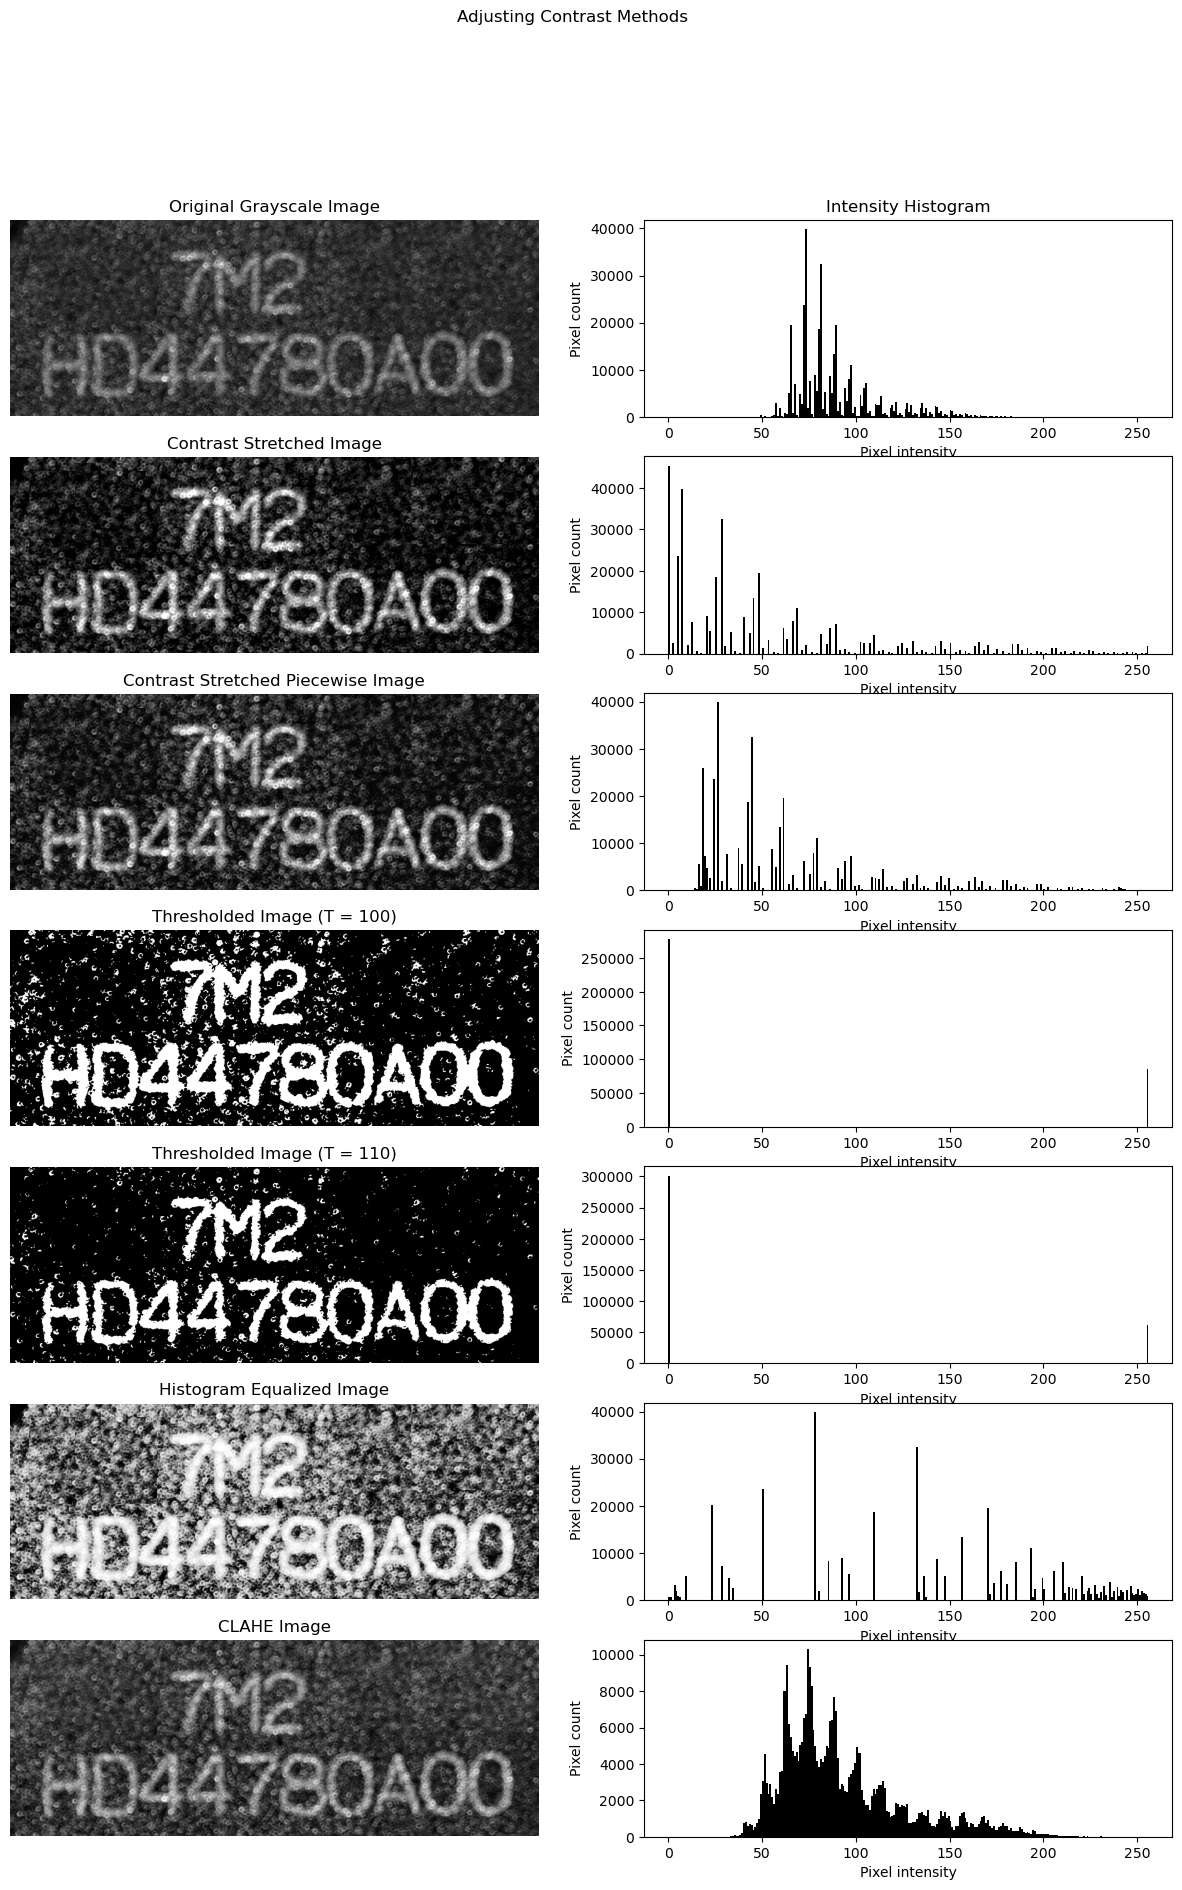

In [10]:
#plot all
contrast_images = [
    test_img_gray, 
    test_img_stretched, 
    test_img_stretched_piecewise, 
    test_img_thresholded_1, 
    test_img_thresholded_2, 
    test_img_eq, 
    test_img_clahe
    ]

contrast_labels = [
    "Original Grayscale Image",
    "Contrast Stretched Image",
    "Contrast Stretched Piecewise Image",
    "Thresholded Image (T = 100)",
    "Thresholded Image (T = 110)",
    "Histogram Equalized Image",
    "CLAHE Image"
    ]
plot_img_hist(contrast_images, "Adjusting Contrast Methods", contrast_labels)

### Task 1 Discussion
Contrast methods are tested on the grayscale image:
1. Simple Contrast Stretching (a = 70, b = 170)
2. Piecewise Constrast Stretching (r1 = 70, r2 = 170, s1 = 20, s2 = 240)
3. 2x Brightness Thresholding (r1 = r2 = 100 and r1 = r2 = 110)
4. Histogram Equalization 
5. CLAHE (Contrast Limited Adaptive Histogram Equalisation) (clipLimit = 1.2, tileGridSize = (4,4))

#### Comments:
- Thresholding gives the best contrast, but also amplify the background noise. Noise is reduced (visually) when threhold is increased from 100 to 110, but this is dependent on the specific image.
- Contrast Stretching provide a good balance of increasing contrast while limiting noise contrast. The parameters of the stretching function is selected after analysing the image intensity histogram.
- Histogram Equalization transform the image without any parameter and attempts to equally distribute the brightness level. However, the due to the high noise level in the original image, the background noise contrast is also significantly amplified, resulting in a noiser image.
- CLAHE performs histogram equalization in small local regions, improving local contrast while limiting noise amplification.

## Task 2: Apply Average filter
Implement and apply a 5×5 averaging filter to the image. Experiment with filters of different sizes. Compare and comment on the results of the respective image smoothing methods.

In [11]:
# Apply avg filter to grayscale images, with kernel size of 1, 3, 5, 7, 9, 11, 13, 15
avg_filter_images = [average_filter(test_img_gray, i) for i in range(1,16,2)]
# Average filter with cv2.blur() function
# avg_filter_images = [cv2.blur(test_img_gray,(i,i)) for i in range(1,16,2)]
avg_filter_labels = [f"{i}x{i} Avg Filter Image" for i in range(1,16,2)]
avg_filter_labels[0] = "Original Image"

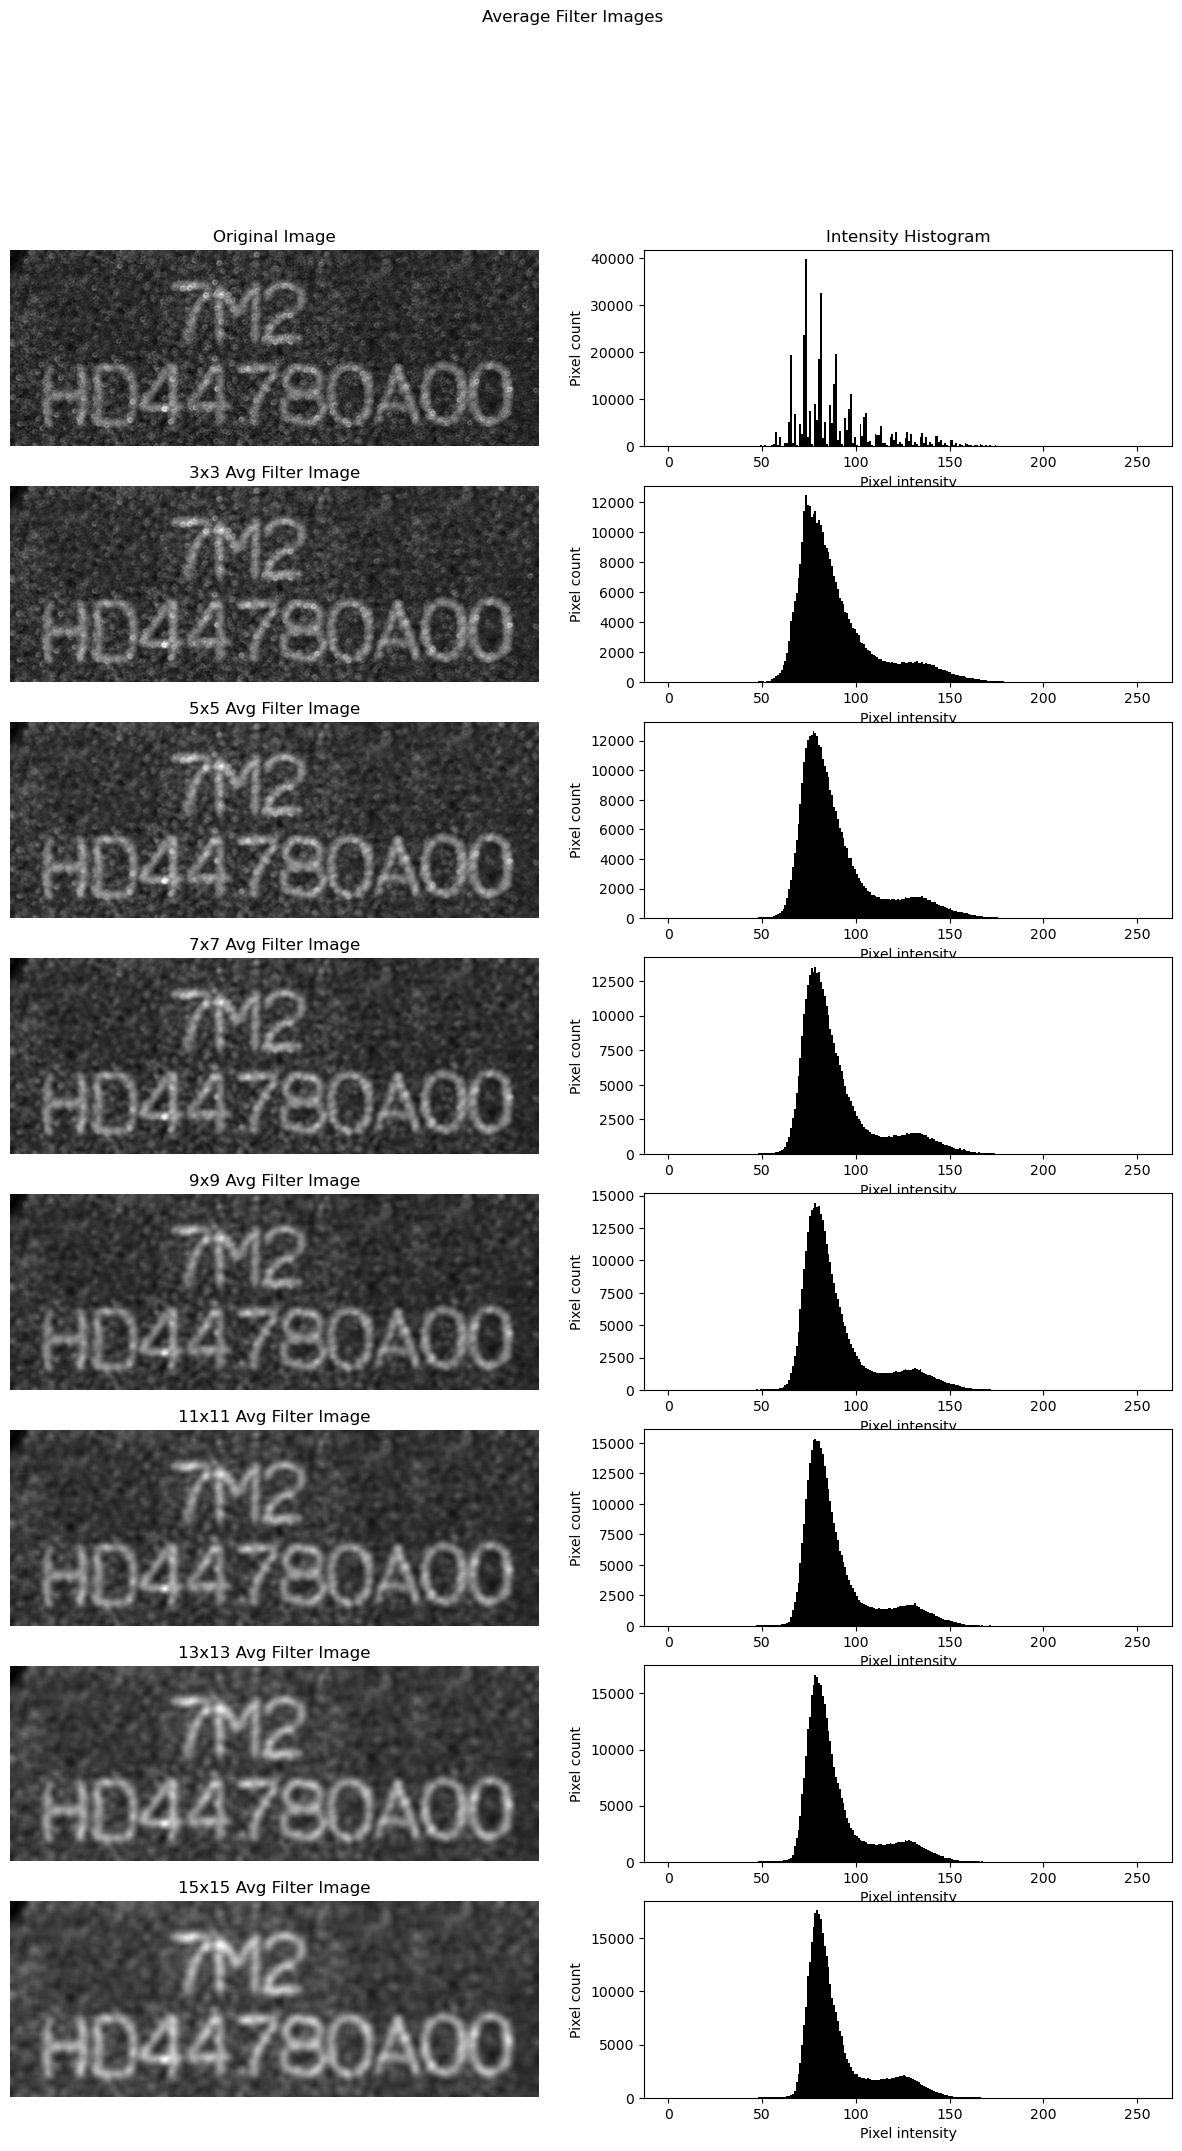

In [12]:
plot_img_hist(avg_filter_images, "Average Filter Images", labels=avg_filter_labels)

### Comments on Average File
Average filter can help to filter out the Gaussian noise in the image. For the given image above, average filter of various odd number sizes are applied. As the kernel size increase, the image appears smoother. However, the image also loses edge sharpness. After visual inspection, kernel size of 7x7 appears to give the best trade off between denoising and minimising loss in sharpness. 

However, after inspecting the original gray scale and average filter images, there are appears to have ring pattern on the image, which looks like impulse noise. Median Filters may be better option to remove them.  
![ring_pattern](./noise.png)

#

In [13]:
# Normal nxn median filter
median_imgs = [median_filter(test_img_gray, i, use_cv2=True) for i in range(1,16,2)]
median_labels = [f"{i}x{i} Median Filter Image" for i in range(1,16,2)]


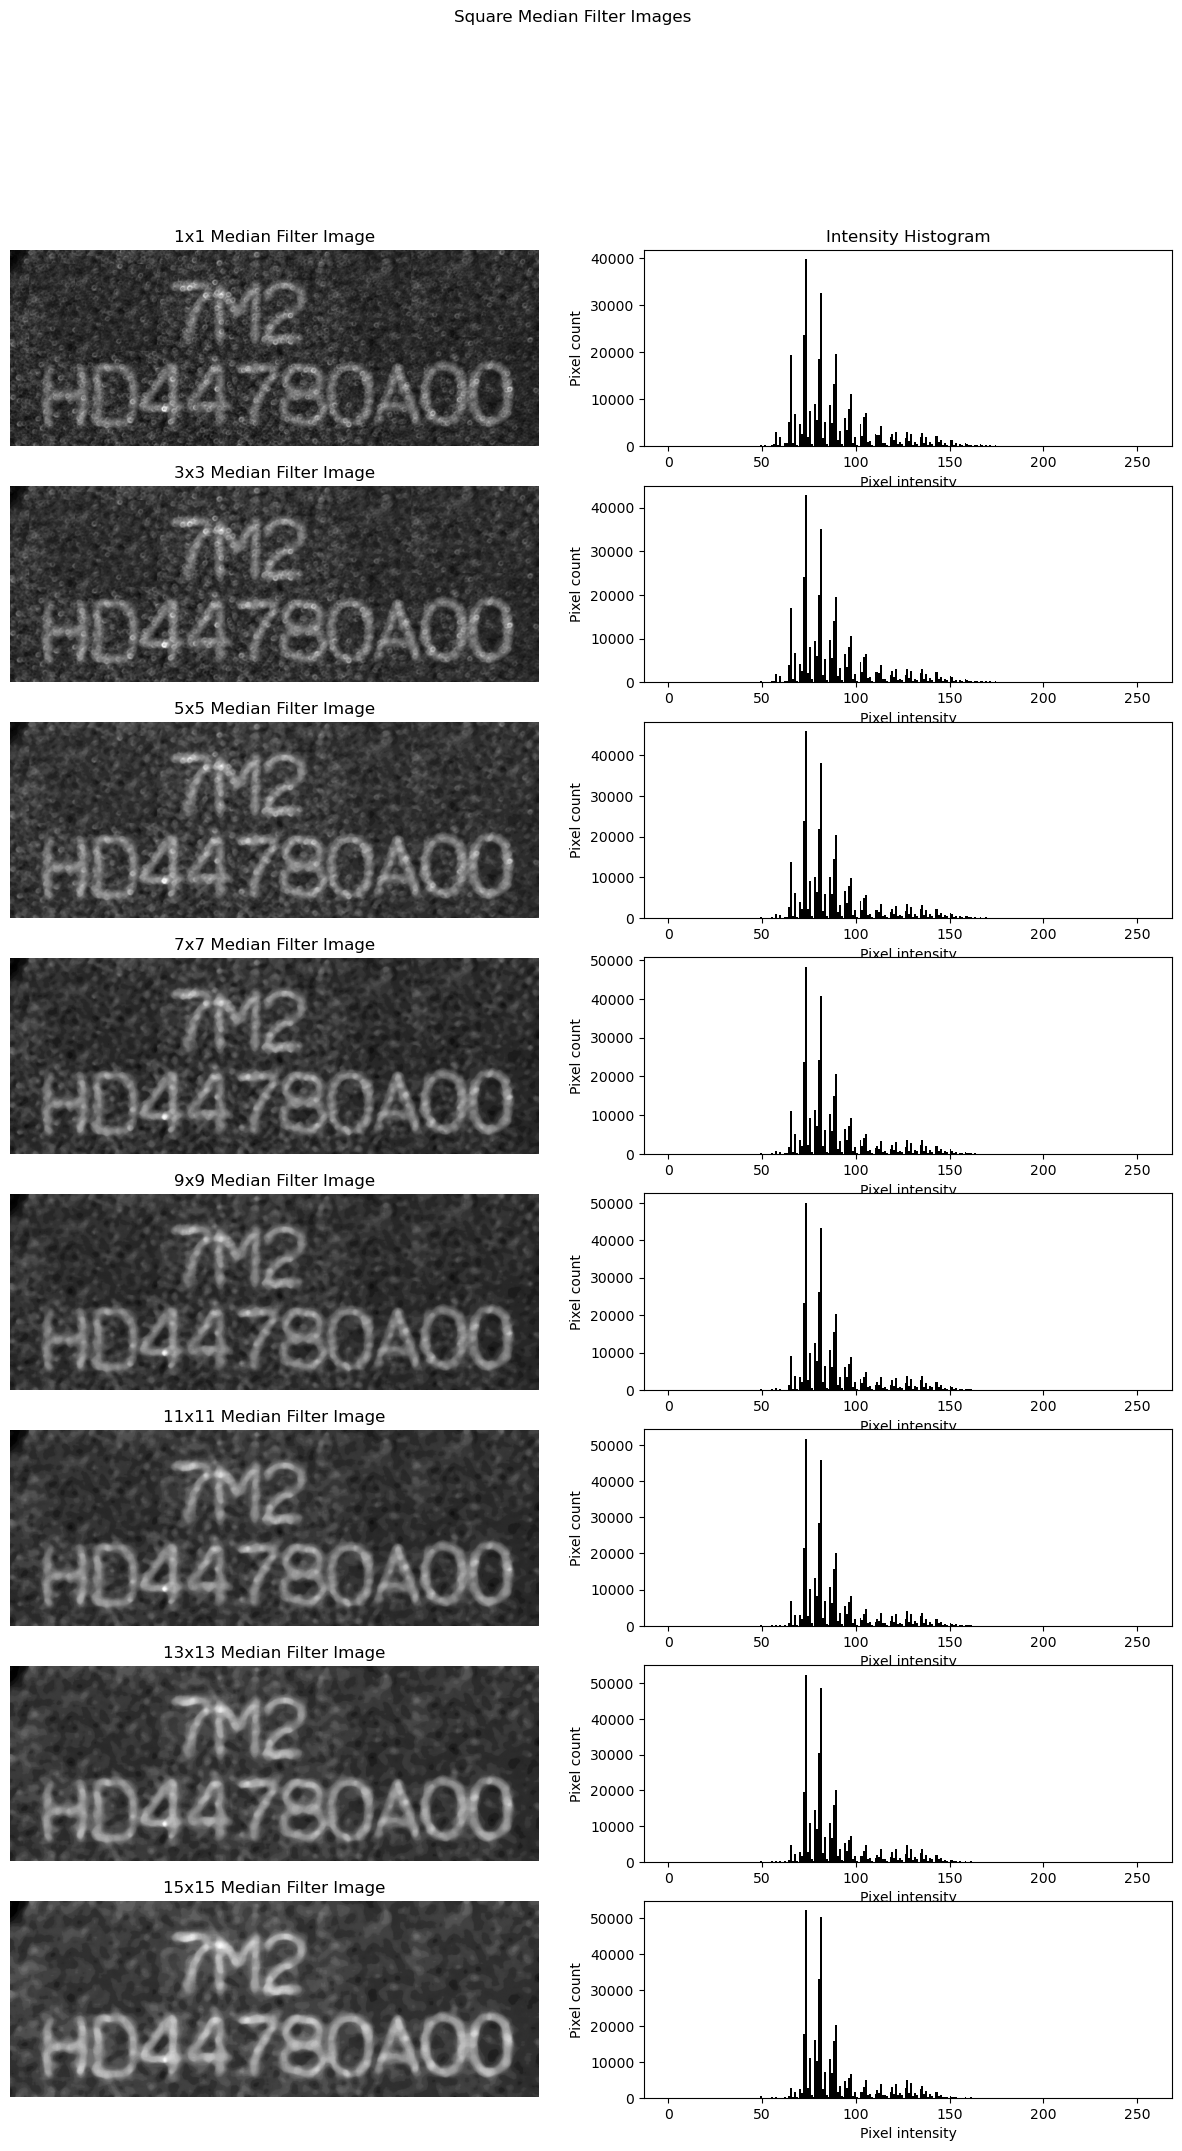

In [14]:
plot_img_hist(median_imgs, "Square Median Filter Images", labels=median_labels)

In [15]:
# + shape median filter
median_t_imgs = [median_filter_t(test_img_gray, i) for i in range(1,16,2)]
median_t_labels = [f"{i}x{i} Median (+) Filter Image" for i in range(1,16,2)]

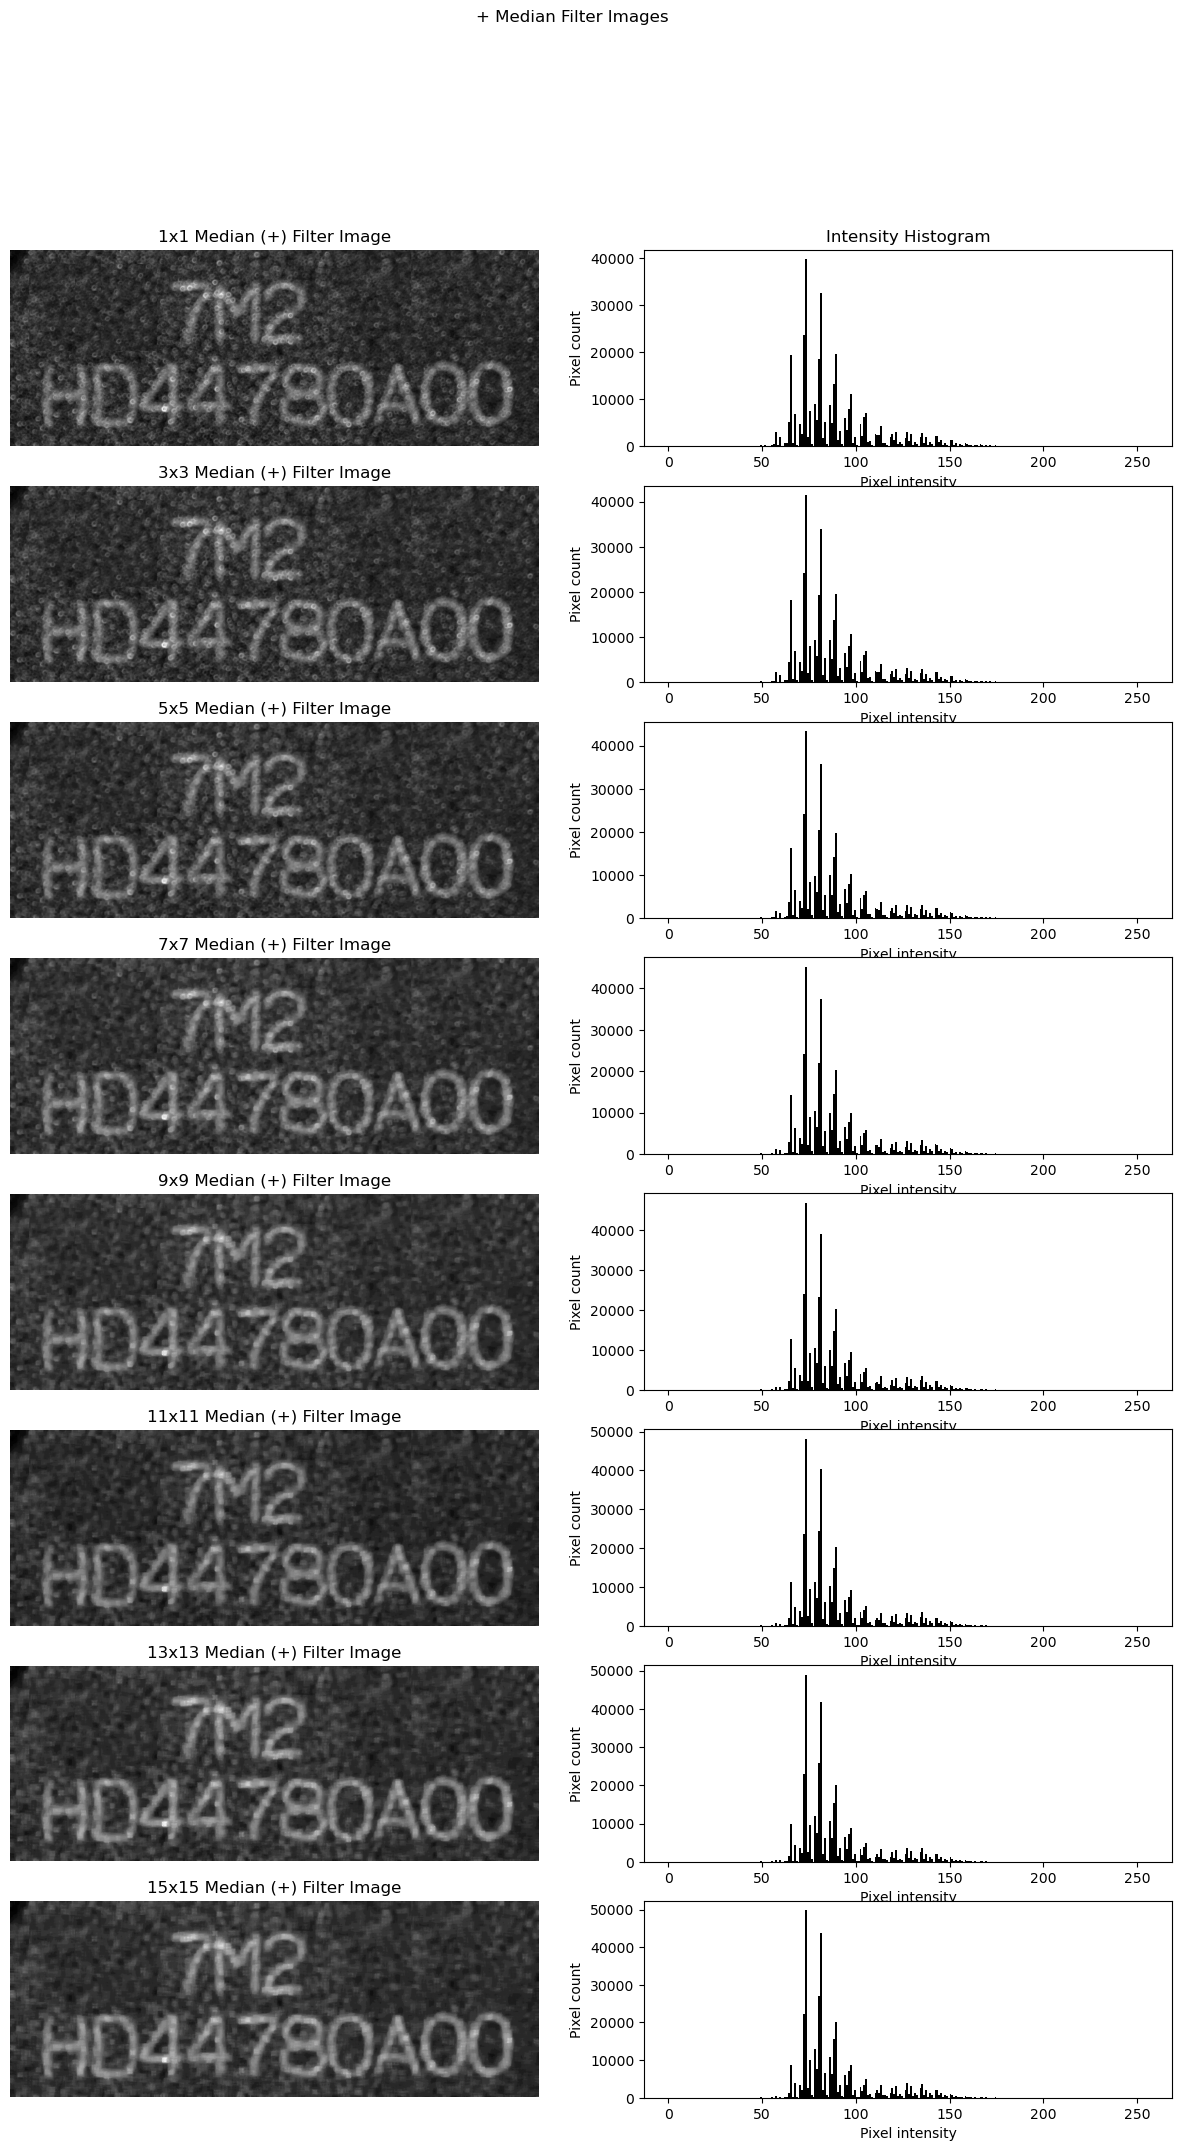

In [16]:
plot_img_hist(median_t_imgs, "+ Median Filter Images", labels=median_t_labels)

In [17]:
# Applying avg filter to 13x13 + median image
median_t_13_img = median_t_imgs[6]
avg_median_t_13_images = [average_filter(median_t_13_img, i, use_cv2=True) for i in range(1,16,2)]
avg_median_t_13_labels = [f"{i}x{i}Avg --> 13x13 Median (+) Filter Image" for i in range(1,16,2)]


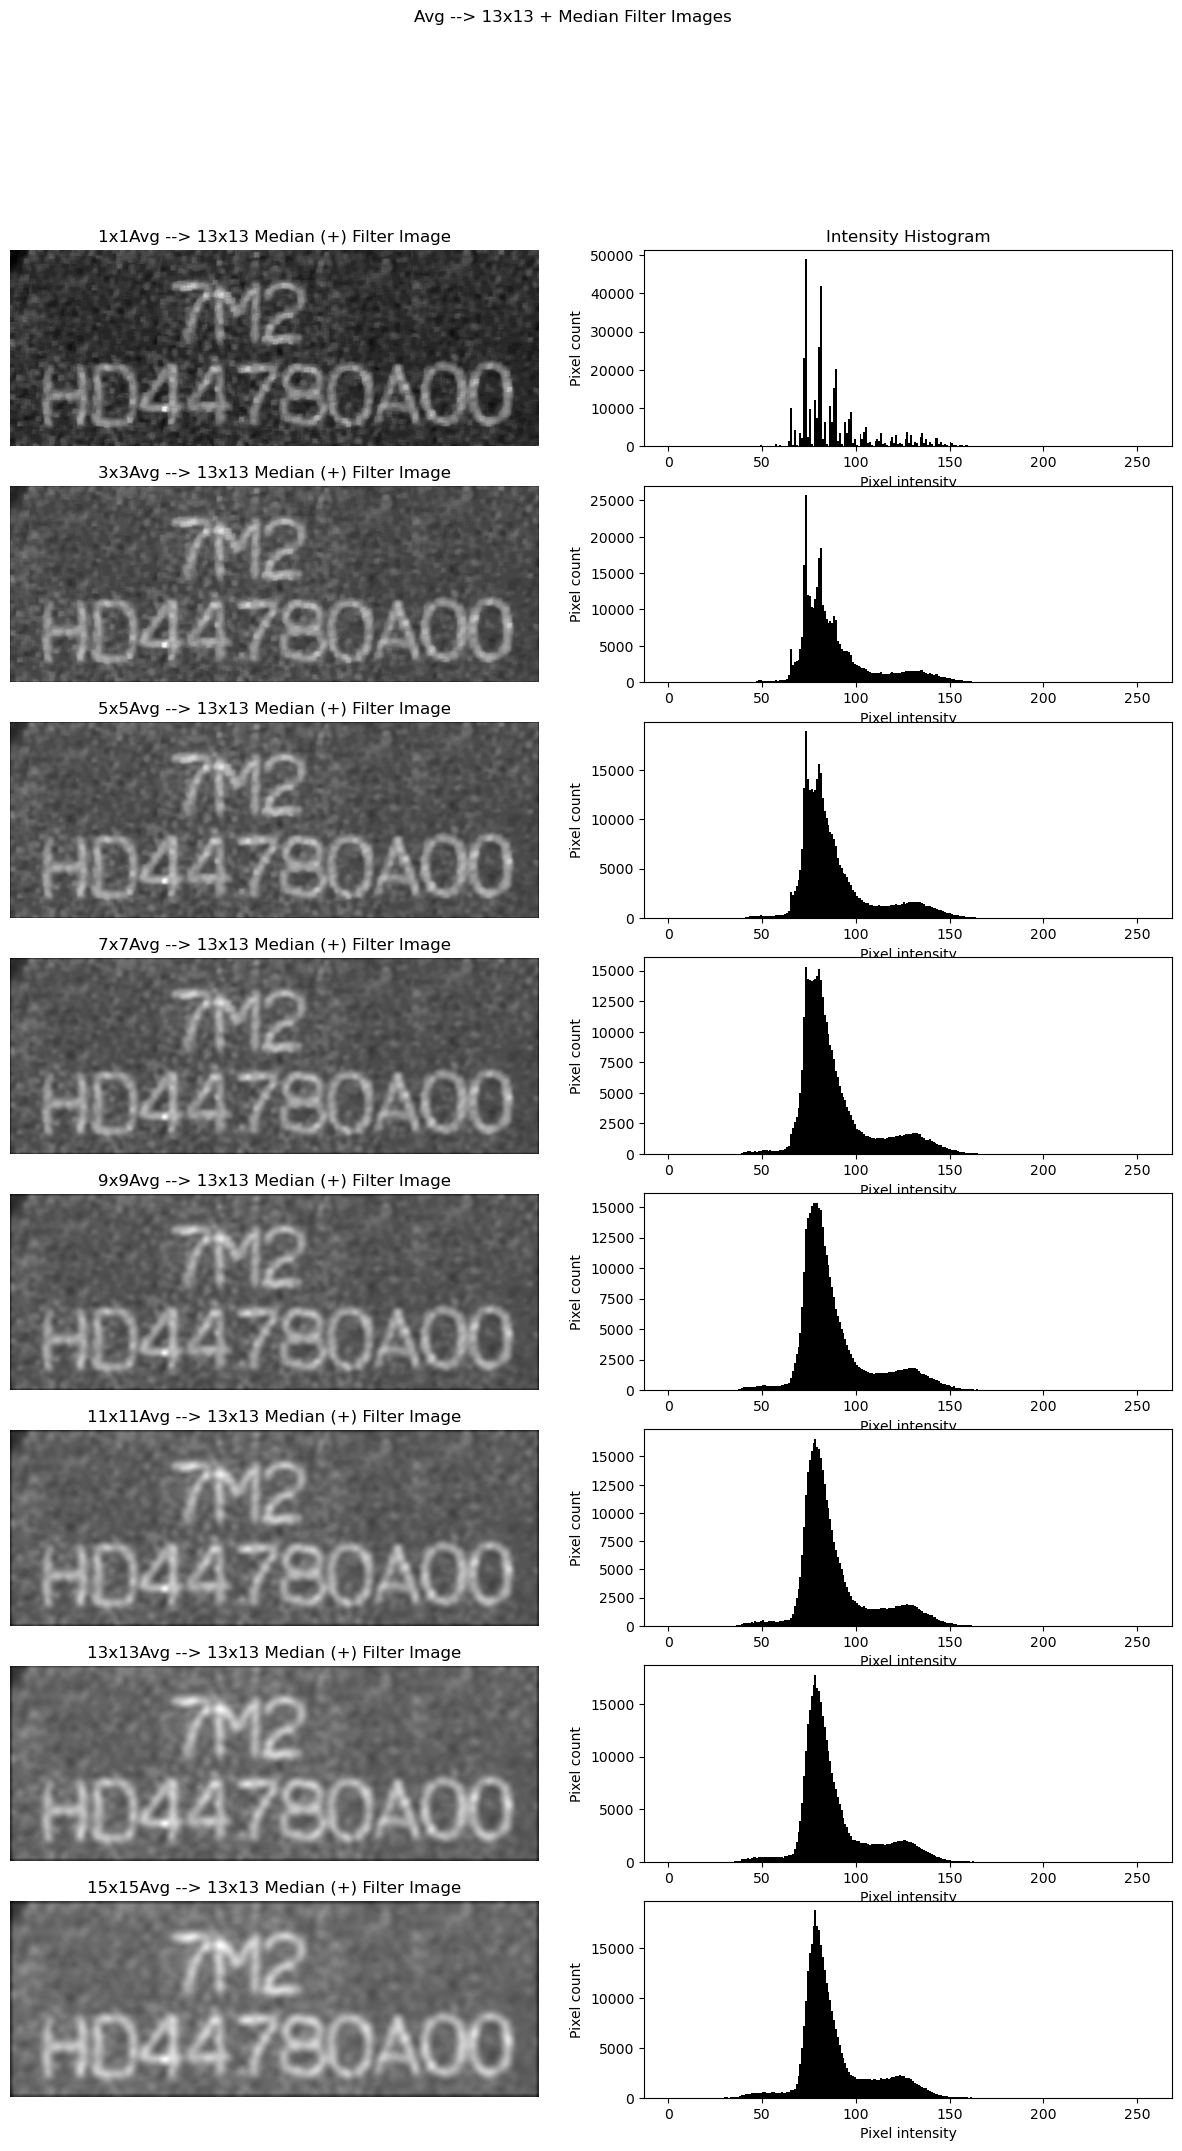

In [18]:
plot_img_hist(avg_median_t_13_images, "Avg --> 13x13 + Median Filter Images", labels=avg_median_t_13_labels)

In [19]:
avg_5_median_t_13_img = avg_median_t_13_images[2]

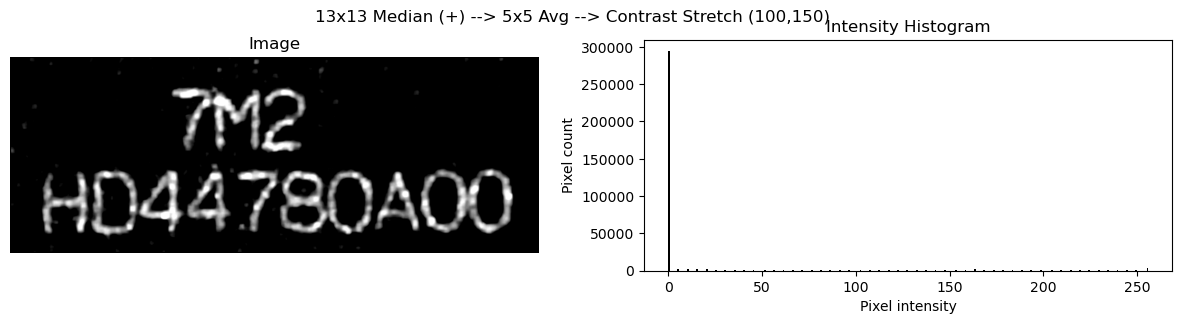

In [20]:
stretch_avg_5_median_t_13_img = contrast_stretching(avg_5_median_t_13_img, 100, 150)
plot_img_hist([stretch_avg_5_median_t_13_img], "13x13 Median (+) --> 5x5 Avg --> Contrast Stretch (100,150)")

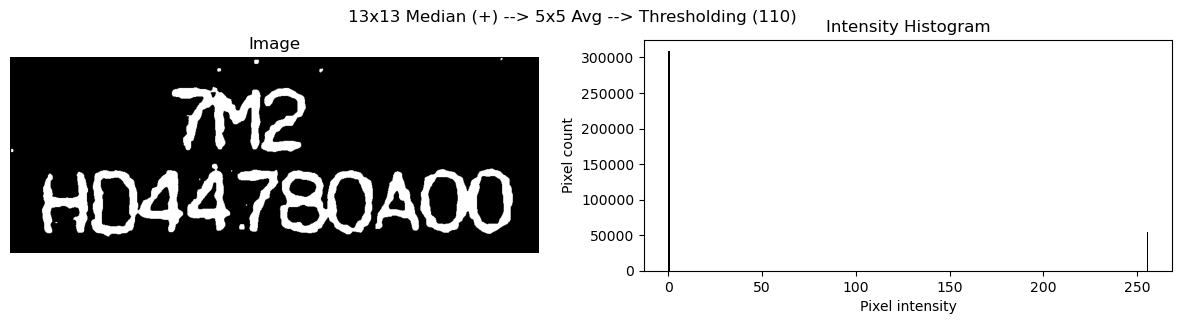

In [21]:
# 13x13 Median (+) --> 5x5 Avg --> Thresholding (110)
thres_avg_5_median_t_13_img = thresholding(avg_5_median_t_13_img, 110)
plot_img_hist([thres_avg_5_median_t_13_img], "13x13 Median (+) --> 5x5 Avg --> Thresholding (110)")

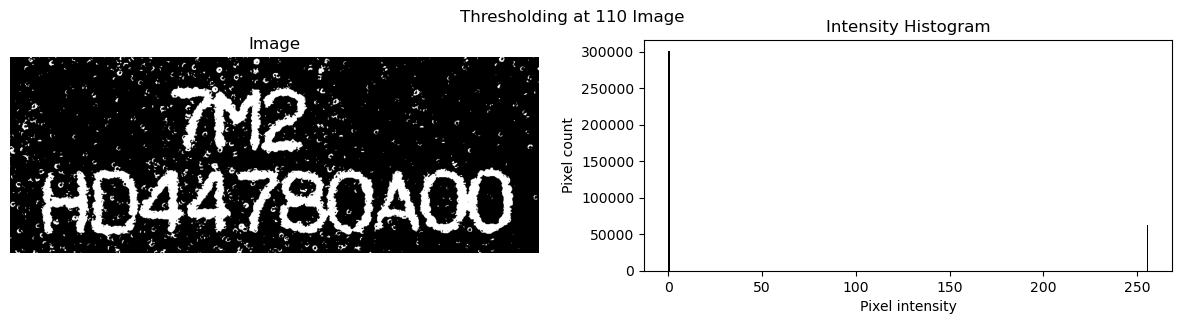

In [22]:
thers_img = thresholding(test_img_gray, 110)
plot_img_hist([thers_img], "Thresholding at 110 Image")

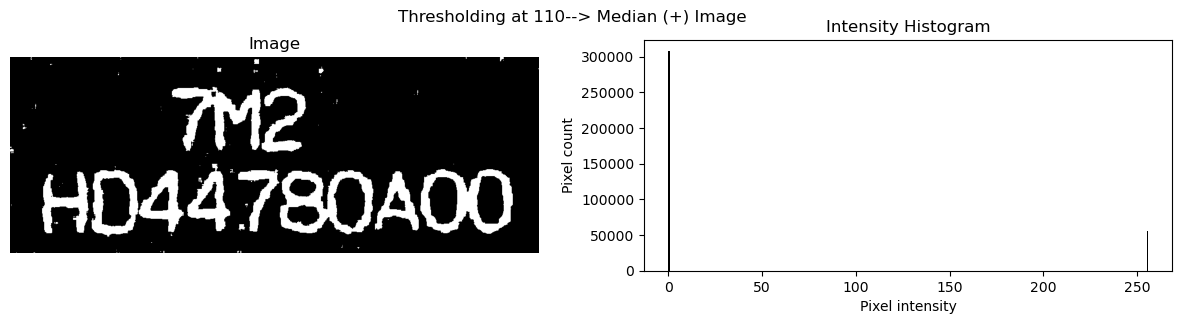

In [23]:
median_thres_img = median_filter_t(thers_img, 15)
plot_img_hist([median_thres_img], "Thresholding at 110--> Median (+) Image")

## Task 3 Create Sub-image
Create a sub-image that includes the line HD44780A00.

In [ ]:
## Open an interactive panel to crop out the sub-image using cv2.selectROI. Returns x,y,w,h
# roi = cv2.selectROI("Select Text Region", test_img_gray)
# cv2.destroyAllWindows()

# x, y, w, h = roi
# print(f"x = {x}, y = {y}, w = {w}, h = {h}")
# sub_image = test_img_gray[y:y+h, x:x+w]

Select a ROI and then press SPACE or ENTER button!
Cancel the selection process by pressing c button!
x = 36, y = 202, w = 912, h = 136


In [30]:
# Save from previous session
x = 36
y = 202
w = 912
h = 136
sub_image = test_img_gray[y:y+h, x:x+w]

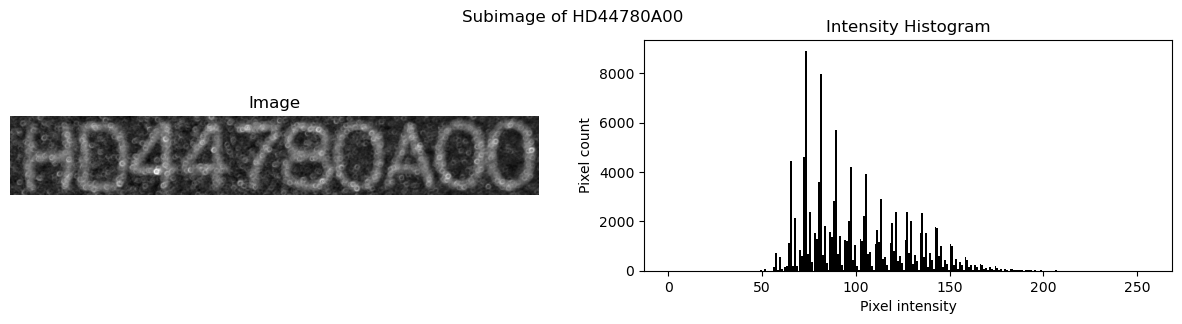

In [31]:
plot_img_hist([sub_image], "Subimage of HD44780A00")

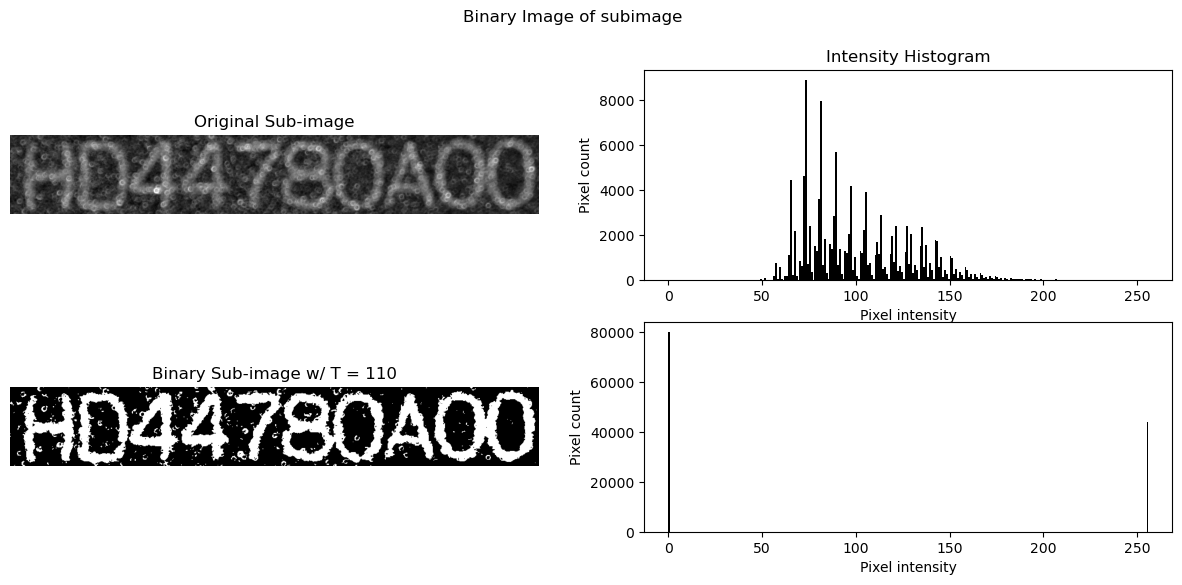

In [32]:
# Task 4
thresh = 110
binary_img = thresholding(sub_image, thresh)
# binary_img
plot_img_hist([sub_image,binary_img], "Binary Image of subimage", labels=["Original Sub-image", f"Binary Sub-image w/ T = {thresh}"])

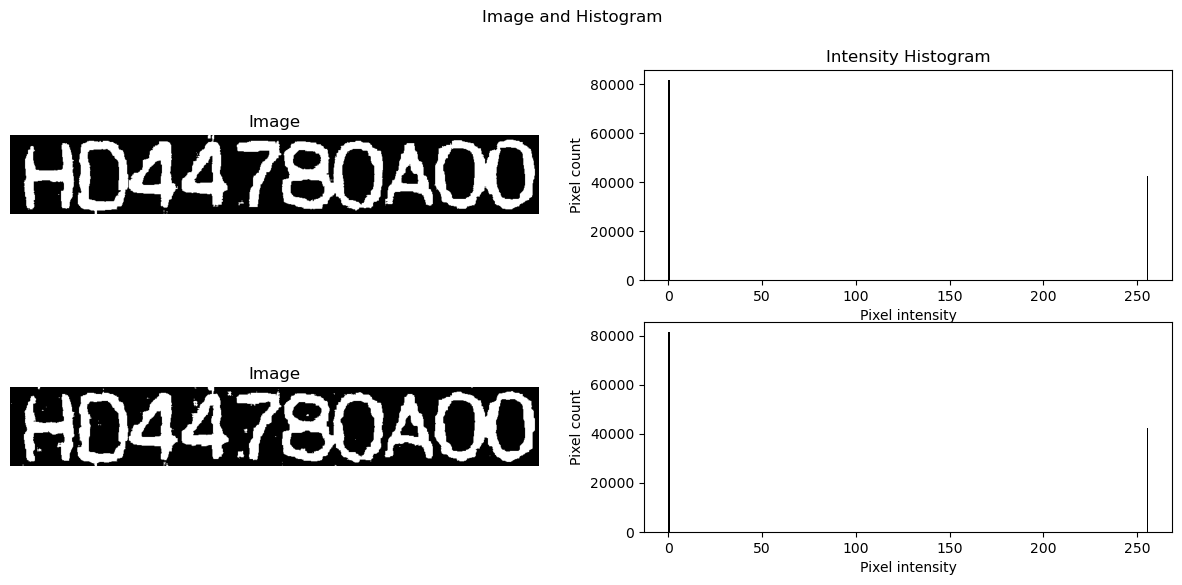

In [33]:
# median_sub = median_filter(binary_img, 13, use_cv2=True)
median_sub = median_filter_t(binary_img, 23)
median_sub2 = median_filter_t(binary_img, 13)

plot_img_hist([median_sub, median_sub2])

## Task 5 Determine Character Outlines
Extract character boundaries from the filtered binary image produced in Task 4.

A 3x3 erosion removes the outer layer of foreground pixels. Subtracting the eroded image from the binary foreground gives the inner outline, including boundaries around character holes.

$$\text{Outline} = B - (B \ominus S)$$

Here, $B$ is the binary foreground and $S$ is a 3x3 square structuring element.


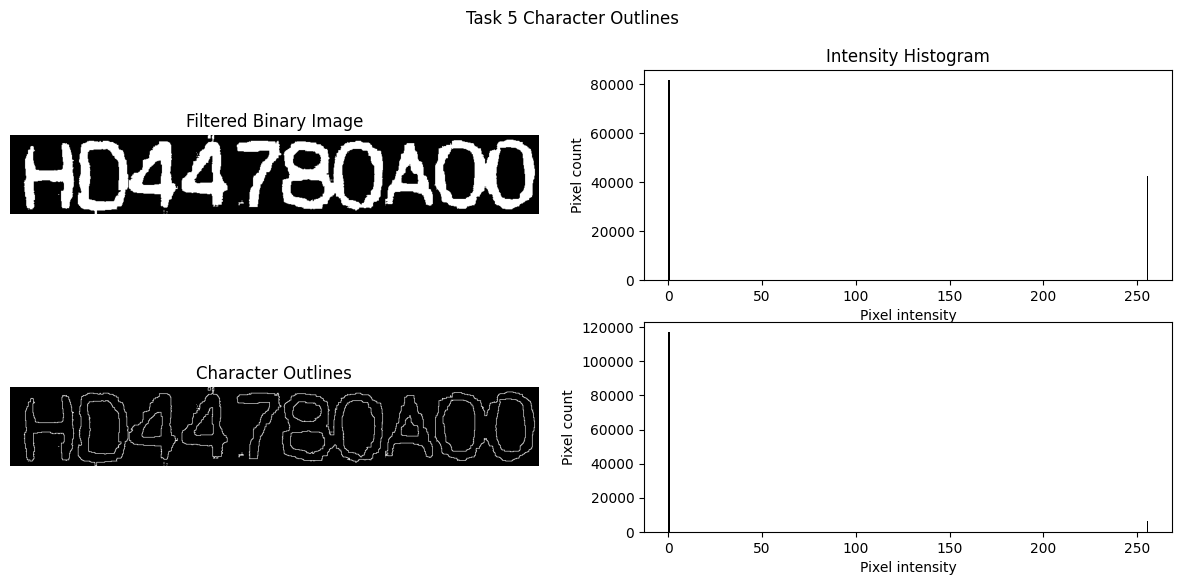

In [7]:
# Reload the module to make newly added functions available in this kernel.
import importlib
import preprocessing
importlib.reload(preprocessing)

# Use the 23x23 cross-median binary result from Task 4.
outline_img = preprocessing.character_outlines(median_sub)

plot_img_hist(
    [median_sub, outline_img],
    "Task 5 Character Outlines",
    labels=["Filtered Binary Image", "Character Outlines"]
)

## Task 6 Connected Components and Bounding Boxes
### Step 1 Prepare a binary image from the grayscale crop
Start with `sub_image`, the grayscale crop from Task 3. Smooth with a 3x3 mean filter. Compute a local mean using a 31x31 window and classify a pixel as foreground when its smoothed intensity is at least 4 gray levels above that local mean. Apply a 5x5 square median filter to the resulting binary image.

$$B(x,y) = 255 \quad \text{if } I_s(x,y) \geq \mu_{31}(x,y) + 4$$

Lecture connections in `Lecture_Notes_export.zip`:
- Chapter 3, Image Preprocessing Part 2, p. 23 introduces linear mask operations and pp. 31–34 discuss median filtering.
- Chapter 4, Segmentation Part 1, pp. 12–16 discuss thresholding. Page 29 includes an adaptive-thresholding application.

The local-mean rule combines filtering with thresholding. The window sizes and offset are implementation parameters selected for this image. They are additional detail to the lecture examples.


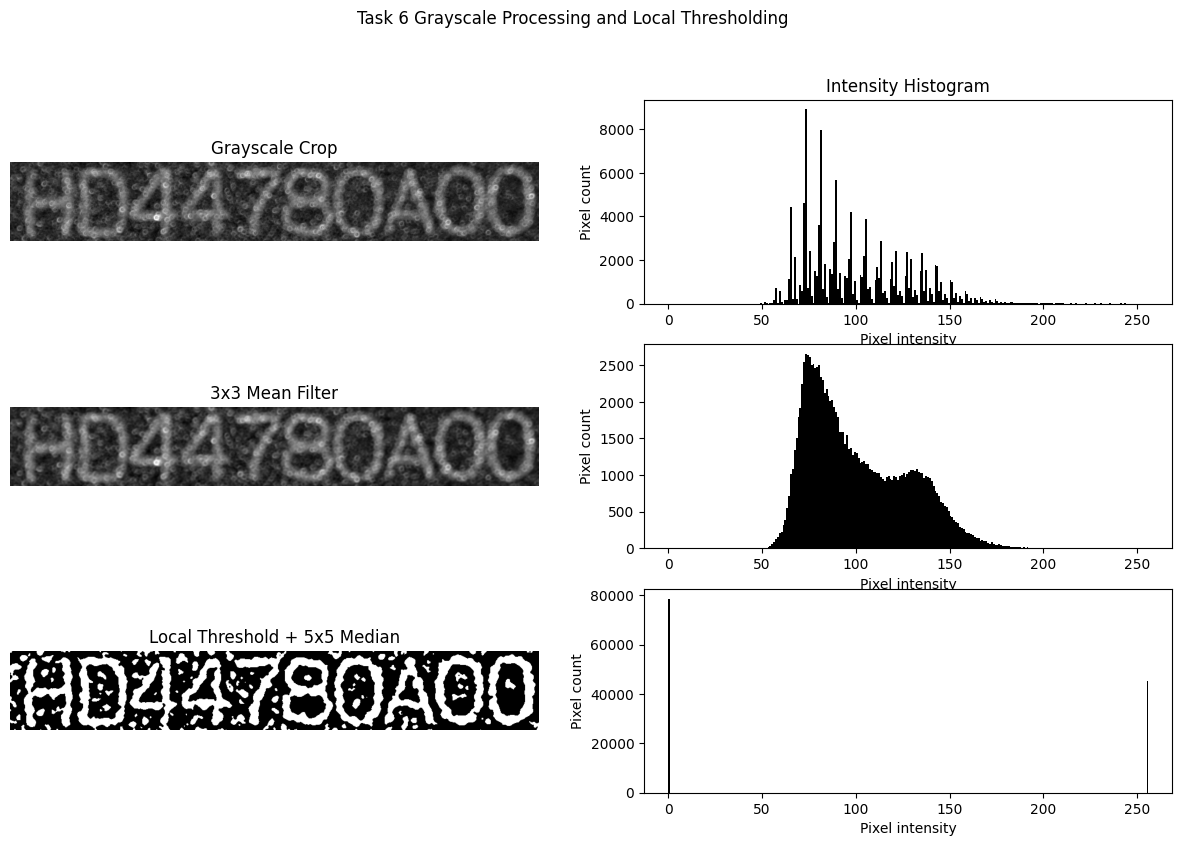

In [5]:
import importlib
import preprocessing
importlib.reload(preprocessing)

smooth_size = 3
background_size = 31
threshold_offset = 4
median_size = 5

task6_smoothed, task6_background, task6_binary = preprocessing.prepare_character_binary(
    sub_image, smooth_size=smooth_size, background_size=background_size,
    offset=threshold_offset, median_size=median_size
)
plot_img_hist(
    [sub_image, task6_smoothed, task6_binary],
    "Task 6 Grayscale Processing and Local Thresholding",
    labels=["Grayscale Crop", "3x3 Mean Filter", "Local Threshold + 5x5 Median"]
)


### Step 2 Compare 4-connectivity and 8-connectivity
The hand-written two-pass implementation follows Chapter 4, Segmentation Part 1, pp. 31–38, especially the classical algorithm on p. 34. The first pass propagates provisional labels and records their equivalences. The second pass resolves labels and computes bounding boxes and areas.

During the first pass, 4-connectivity uses the upper and left neighbors. 8-connectivity additionally uses the upper-left and upper-right neighbors.

Use a minimum area of 500 foreground pixels to exclude small regions. This image-specific setting has the same value for both connectivity modes. Area measurement is covered on pp. 39–40. The component label matrix retains all foreground regions.


In [6]:
min_component_area = 500
connectivity_results = {}

for connectivity in (4, 8):
    labels, components = preprocessing.connected_components(
        task6_binary, connectivity=connectivity, min_area=min_component_area
    )
    connectivity_results[connectivity] = {"labels": labels, "components": components}
    print(f"{connectivity}-connectivity")
    print(f"  All foreground components: {int(labels.max())}")
    print(f"  Components with area >= {min_component_area}: {len(components)}")
    for index, component in enumerate(components, start=1):
        print(f"  {index}: {component}")

# A diagonal arrangement verifies the difference between the two neighborhoods.
diagonal_image = np.eye(3, dtype=np.uint8) * 255
_, diagonal_four = preprocessing.connected_components(diagonal_image, connectivity=4)
_, diagonal_eight = preprocessing.connected_components(diagonal_image, connectivity=8)
assert len(diagonal_four) == 3
assert len(diagonal_eight) == 1
print("Diagonal check passed: 4-connectivity gives 3 regions; 8 gives 1.")


4-connectivity
  All foreground components: 138
  Components with area >= 500: 10
  1: {'label': 38, 'x': 24, 'y': 11, 'area': 3932, 'width': 84, 'height': 121}
  2: {'label': 24, 'x': 116, 'y': 2, 'area': 4302, 'width': 87, 'height': 134}
  3: {'label': 36, 'x': 206, 'y': 10, 'area': 3517, 'width': 82, 'height': 126}
  4: {'label': 40, 'x': 296, 'y': 12, 'area': 3364, 'width': 87, 'height': 116}
  5: {'label': 14, 'x': 387, 'y': 0, 'area': 2756, 'width': 90, 'height': 128}
  6: {'label': 39, 'x': 469, 'y': 11, 'area': 4467, 'width': 88, 'height': 117}
  7: {'label': 34, 'x': 559, 'y': 7, 'area': 3973, 'width': 85, 'height': 124}
  8: {'label': 37, 'x': 646, 'y': 10, 'area': 3290, 'width': 91, 'height': 117}
  9: {'label': 31, 'x': 731, 'y': 6, 'area': 4086, 'width': 86, 'height': 122}
  10: {'label': 30, 'x': 824, 'y': 5, 'area': 4082, 'width': 82, 'height': 124}
8-connectivity
  All foreground components: 138
  Components with area >= 500: 10
  1: {'label': 38, 'x': 24, 'y': 11, 'are

### Step 3 Draw one bounding box per retained component
Draw components in left-to-right order. The underlying image shows the retained foreground labels after area filtering. Bounding boxes are relative to the grayscale crop. Each numbered box corresponds directly to a connected component.


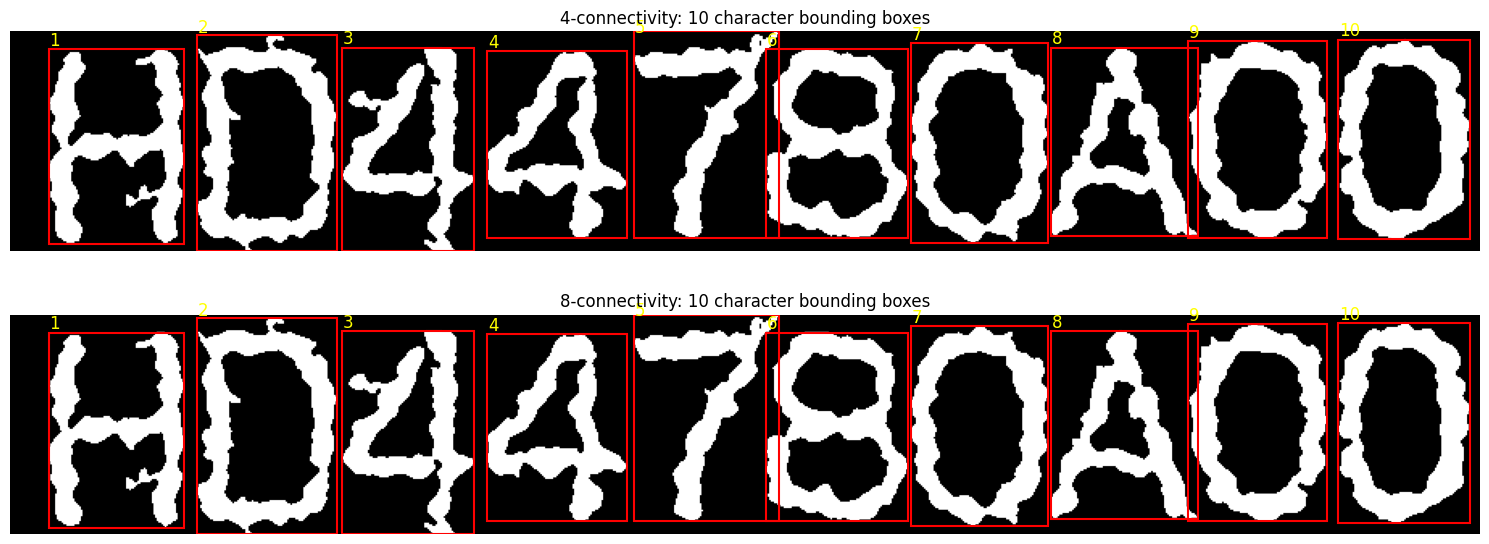

In [7]:
figure, axes = plt.subplots(2, 1, figsize=(15, 6))
for axis, connectivity in zip(axes, (4, 8)):
    result = connectivity_results[connectivity]
    components = result["components"]
    retained_labels = [component["label"] for component in components]
    retained_binary = np.isin(result["labels"], retained_labels).astype(np.uint8) * 255
    axis.imshow(retained_binary, cmap="gray", vmin=0, vmax=255)
    for index, component in enumerate(components, start=1):
        x, y = component["x"], component["y"]
        width, height = component["width"], component["height"]
        axis.add_patch(plt.Rectangle((x - 0.5, y - 0.5), width, height,
                                    fill=False, edgecolor="red", linewidth=1.5))
        axis.text(x, max(y - 3, 0), str(index), color="yellow", fontsize=12)
    axis.set_title(f"{connectivity}-connectivity: {len(components)} character bounding boxes")
    axis.axis("off")
figure.tight_layout()
plt.show()


### Observations and parameter limits
On the supplied image, both connectivity modes produce 138 foreground regions. Applying the 500-pixel minimum area retains 10 character components. Each character box is computed from one connected component.

The local mean compensates for slowly varying background intensity and reduces weak bridges between adjacent strokes. Detached background texture is removed through area filtering. Some background pixels remain attached to characters.

The filter windows, threshold offset and area cutoff were investigated on this image. Different illumination, resolution or stroke thickness may require retuning. Check the binary image and bounding boxes visually when changing parameters. The function inputs contain no expected character identities or target component count.
